In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.calibration import calibration_curve

sns.set_theme(style="whitegrid")

In [2]:
PROJECT_ROOT = Path("..").resolve()
MODELS_DIR = PROJECT_ROOT / "models"
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "train_features_v2.parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

bundle = joblib.load(MODELS_DIR / "lgbm_v3_tuned.joblib")
oof_blend = pd.read_parquet(MODELS_DIR / "oof_blend_v3_final.parquet")
df = pd.read_parquet(DATA_PATH)

In [3]:
feature_cols = bundle["feature_cols"]
model_fold0 = bundle["folds"][0]

print(f"Loaded {len(df):,} rows | {len(feature_cols)} selected v3 features")

Loaded 307,511 rows | 220 selected v3 features


In [4]:
# Calibration curve & Decile Lift table on final blend OOF
y_true = oof_blend["TARGET"].values
y_pred = oof_blend["oof_pred"].values

In [5]:
# Decile Lift analysis
decile_df = pd.DataFrame({"y_true": y_true, "pd": y_pred})
decile_df["decile"] = pd.qcut(decile_df["pd"], q=10, labels=range(1, 11))

lift_table = (
    decile_df.groupby("decile", observed=False)
    .agg(
        clients=("y_true", "count"),
        defaults=("y_true", "sum"),
        avg_pred_pd=("pd", "mean"),
        actual_dr=("y_true", "mean"),
    )
    .sort_index(ascending=False)
)
lift_table["cum_defaults_pct"] = lift_table["defaults"].cumsum() / lift_table["defaults"].sum()
lift_table["lift"] = lift_table["actual_dr"] / y_true.mean()

display(lift_table.style.format({
    "clients": "{:,}",
    "defaults": "{:,}",
    "avg_pred_pd": "{:.2%}",
    "actual_dr": "{:.2%}",
    "cum_defaults_pct": "{:.1%}",
    "lift": "{:.2f}x",
}))

,clients,defaults,avg_pred_pd,actual_dr,cum_defaults_pct,lift
decile,,,,,,
10,"30,751","9,624",31.01%,31.30%,38.8%,3.88x
9,"30,751","4,837",14.99%,15.73%,58.3%,1.95x
8,"30,751","3,239",9.89%,10.53%,71.3%,1.30x
7,"30,751","2,194",7.09%,7.13%,80.1%,0.88x
6,"30,751","1,603",5.26%,5.21%,86.6%,0.65x
5,"30,751","1,159",3.98%,3.77%,91.3%,0.47x
4,"30,751",833,3.02%,2.71%,94.6%,0.34x
3,"30,751",657,2.24%,2.14%,97.3%,0.26x
2,"30,751",433,1.58%,1.41%,99.0%,0.17x


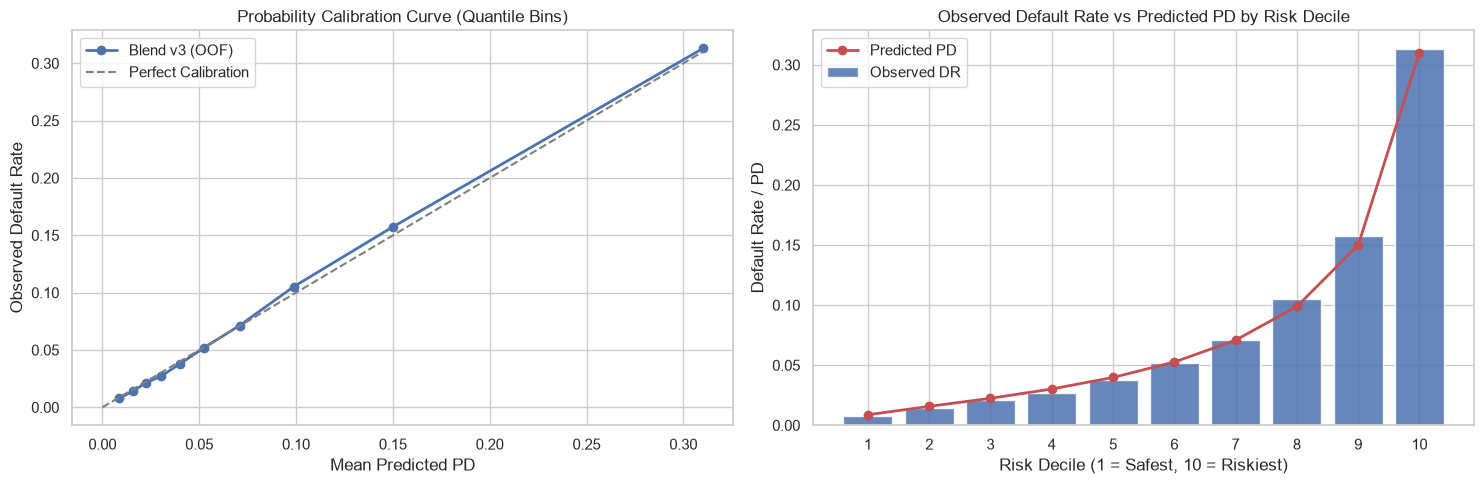

In [6]:
# Plot Calibration + Decile Default Rate
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

prob_true, prob_pred = calibration_curve(y_true, y_pred, n_bins=10, strategy="quantile")
axes[0].plot(prob_pred, prob_true, marker="o", linewidth=2, label="Blend v3 (OOF)")
axes[0].plot([0, prob_pred.max()], [0, prob_pred.max()], linestyle="--", color="gray", label="Perfect Calibration")
axes[0].set_title("Probability Calibration Curve (Quantile Bins)")
axes[0].set_xlabel("Mean Predicted PD")
axes[0].set_ylabel("Observed Default Rate")
axes[0].legend()

lift_plot = lift_table.sort_index()
axes[1].bar(lift_plot.index.astype(str), lift_plot["actual_dr"], color="#4C72B0", alpha=0.85, label="Observed DR")
axes[1].plot(range(10), lift_plot["avg_pred_pd"], color="#C44E52", marker="o", linewidth=2, label="Predicted PD")
axes[1].set_title("Observed Default Rate vs Predicted PD by Risk Decile")
axes[1].set_xlabel("Risk Decile (1 = Safest, 10 = Riskiest)")
axes[1].set_ylabel("Default Rate / PD")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "calibration_and_deciles.png", dpi=150, bbox_inches="tight")
plt.show()

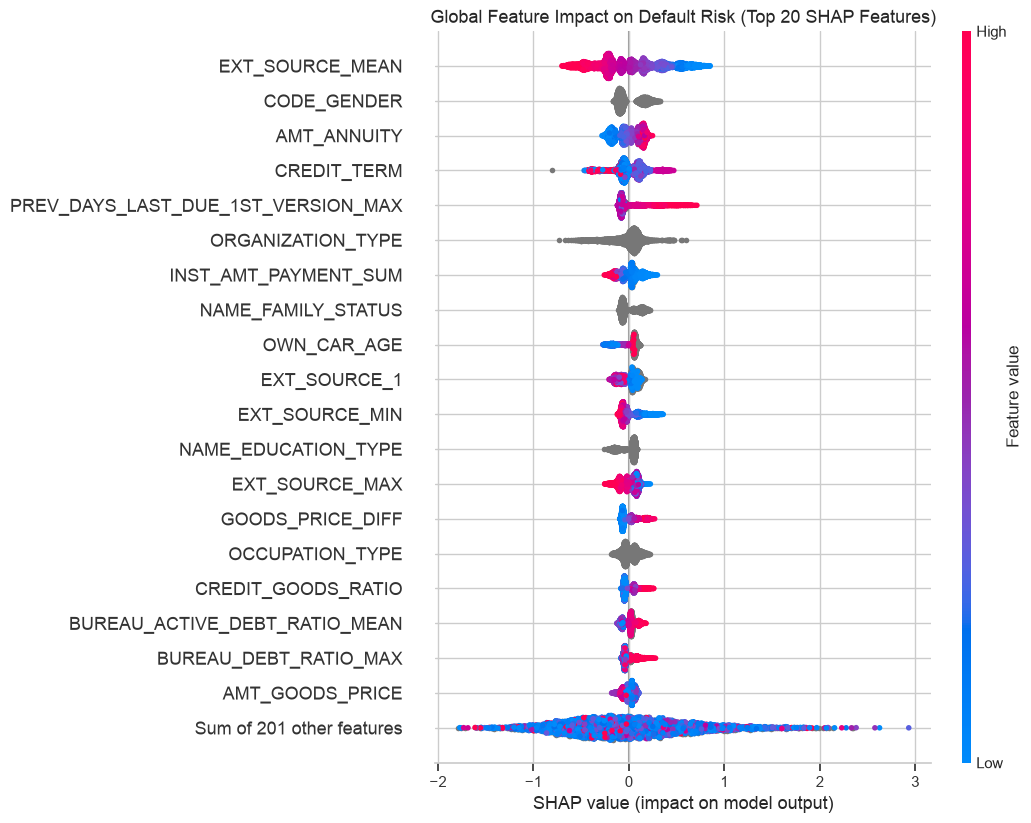

In [7]:
# Compute TreeSHAP on a representative 5,000-client sample
sample_idx = df.sample(n=5000, random_state=42).index
X_sample = df.loc[sample_idx, feature_cols]

explainer = shap.TreeExplainer(model_fold0)
shap_values = explainer(X_sample)

# Handle binary output shape if SHAP returns (N, F, 2)
if shap_values.values.ndim == 3:
    shap_exp = shap_values[:, :, 1]
else:
    shap_exp = shap_values

plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_exp, max_display=20, show=False)
plt.title("Global Feature Impact on Default Risk (Top 20 SHAP Features)", fontsize=13)
plt.savefig(FIG_DIR / "shap_beeswarm_top20.png", dpi=150, bbox_inches="tight")
plt.show()


=== HIGH-RISK APPLICANT (DECLINE) | SK_ID_CURR=395476 | Predicted PD=84.08% ===
  1. EXT_SOURCE_MEAN                     = 0.05449759239367346 | SHAP: +0.7694 (INCREASES risk (+))
  2. EXT_SOURCE_MIN                      = 0.03403590388830004 | SHAP: +0.3216 (INCREASES risk (+))
  3. CC_12M_CNT_DRAWINGS_ATM_CURRENT_MEAN = 2.75         | SHAP: +0.2699 (INCREASES risk (+))
  4. EXT_SOURCE_PROD                     = 0.0025513068802160443 | SHAP: +0.2548 (INCREASES risk (+))
  5. EXT_SOURCE_MAX                      = 0.07495928089904688 | SHAP: +0.1995 (INCREASES risk (+))

=== LOW-RISK APPLICANT (APPROVE) | SK_ID_CURR=171402 | Predicted PD=0.18% ===
  1. EXT_SOURCE_MEAN                     = 0.7441352666020797 | SHAP: -0.5889 (DECREASES risk (-))
  2. CREDIT_TERM                         = 0.10293703979482088 | SHAP: -0.4578 (DECREASES risk (-))
  3. INST_AMT_PAYMENT_SUM                = 3.1131785e+06 | SHAP: -0.1968 (DECREASES risk (-))
  4. PREV_DAYS_TERMINATION_MAX           = -20.0   

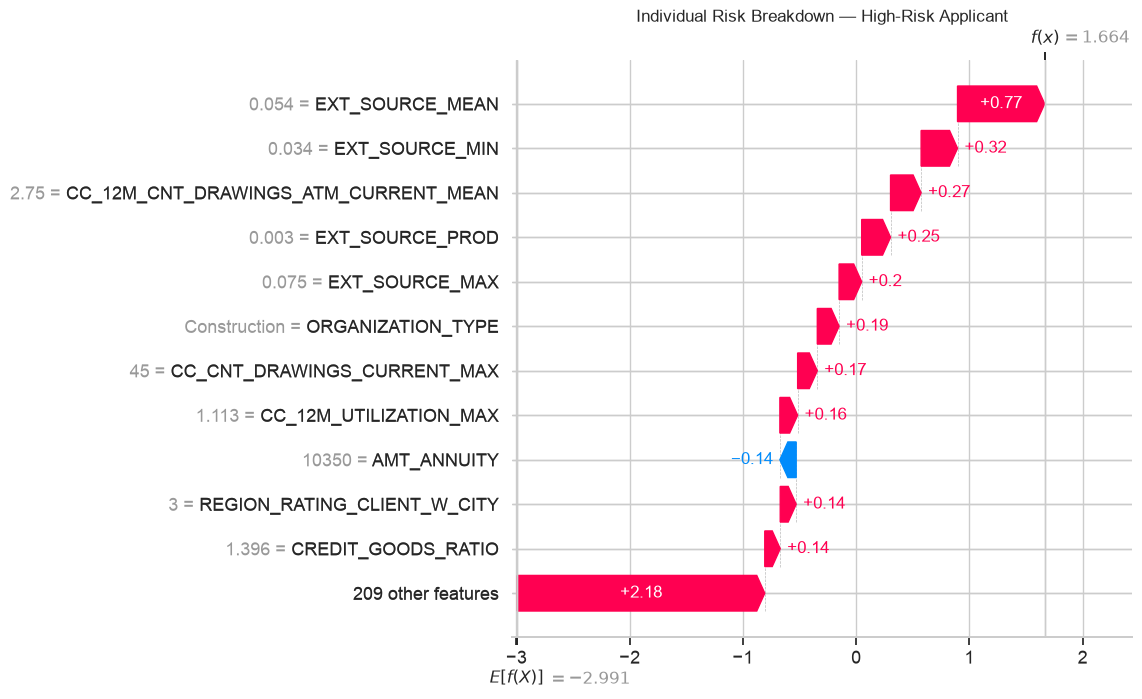

In [8]:
# Pick 1 high-risk client (rejection candidate) and 1 low-risk client (approval candidate)
sample_preds = model_fold0.predict_proba(X_sample)[:, 1]
high_risk_pos = int(np.argmax(sample_preds))
low_risk_pos = int(np.argmin(sample_preds))

def print_reason_codes(pos: int, label: str, top_k: int = 5) -> None:
    sv = shap_exp[pos].values
    vals = X_sample.iloc[pos]
    pd_val = sample_preds[pos]
    order = np.argsort(np.abs(sv))[::-1][:top_k]

    print(f"\n=== {label} | SK_ID_CURR={df.loc[sample_idx[pos], 'SK_ID_CURR']} | Predicted PD={pd_val:.2%} ===")
    for rank, idx in enumerate(order, start=1):
        feat = feature_cols[idx]
        direction = "INCREASES risk (+)" if sv[idx] > 0 else "DECREASES risk (-)"
        print(f"  {rank}. {feat:<35} = {str(vals.iloc[idx]):<12} | SHAP: {sv[idx]:+.4f} ({direction})")

print_reason_codes(high_risk_pos, "HIGH-RISK APPLICANT (DECLINE)")
print_reason_codes(low_risk_pos, "LOW-RISK APPLICANT (APPROVE)")

# Waterfall plot for high-risk applicant
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_exp[high_risk_pos], max_display=12, show=False)
plt.title("Individual Risk Breakdown — High-Risk Applicant", fontsize=12)
plt.savefig(FIG_DIR / "shap_waterfall_high_risk.png", dpi=150, bbox_inches="tight")
plt.show()

## Key Model Validation & XAI Findings

1. **Probability Calibration (`blend_v3_final` OOF):**
   - Predicted probabilities align closely with observed default rates across all 10 quantile bins: `31.01%` predicted PD vs. `31.30%` actual default rate in Decile 10, and `0.88%` vs. `0.80%` in Decile 1.
   - *Action:* No post-hoc calibration (Platt scaling or Isotonic regression) is needed; raw ensemble probabilities are directly usable for Expected Loss estimation ($EL = PD \times LGD \times EAD$) and risk-based pricing.

2. **Risk Concentration & Decile Lift:**
   - The top risk decile (10% of applicants, `n = 30,751`) captures **`38.8%`** of all defaults (**`3.88x`** lift), while the top two deciles capture **`58.3%`** of defaults.
   - Observed default risk spans a **39x** range between the riskiest and safest deciles (`31.30%` vs. `0.80%`), confirming strong rank-ordering across the entire score distribution.

3. **Global Explainability (TreeSHAP on `lgbm_v3_tuned`):**
   - Engineered domain and relational features dominate global model impact alongside external bureau scores: `EXT_SOURCE_MEAN` (#1), `CREDIT_TERM`, `PREV_DAYS_LAST_DUE_1ST_VERSION_MAX`, `INST_AMT_PAYMENT_SUM`, `GOODS_PRICE_DIFF`, `CREDIT_GOODS_RATIO`, `BUREAU_ACTIVE_DEBT_RATIO_MEAN`, and `BUREAU_DEBT_RATIO_MAX`.
   - Feature directionality aligns with credit risk fundamentals: higher external scores and larger historical repayment totals lower PD, whereas high bureau debt ratios, excess loan-to-goods ratios, and high credit card utilization push PD upward.

4. **Local Explanations & Adverse Action Reason Codes:**
   - *High-Risk Decline (`SK_ID_CURR=395476`, PD = `84.08%`):* Log-odds shift from base value `E[f(X)] = -2.991` to `f(x) = +1.664`, driven by critically low external scores (`EXT_SOURCE_MEAN = 0.054`, `+0.77`), frequent ATM cash advances (`2.75` avg/month over 12M, `+0.27`), over-limit card utilization (`1.113`, `+0.16`), employment sector (`Construction`, `+0.19`), and high `CREDIT_GOODS_RATIO` (`1.396`, `+0.14`).
   - *Low-Risk Approval (`SK_ID_CURR=171402`, PD = `0.18%`):* Driven by strong external scores (`EXT_SOURCE_MEAN = 0.744`, `-0.59`), short/manageable `CREDIT_TERM` (`0.103`, `-0.46`), substantial cumulative installment repayments (`3.11M`, `-0.20`), and recent clean loan termination (`-20` days, `-0.20`).

5. **Production & Fair Lending Notes:**
   - *Reason-Code Grouping:* Raw top-5 SHAP lists can repeat correlated features from the same family (e.g., `EXT_SOURCE_MEAN/MIN/MAX/PROD`). In the inference API, SHAP values should be aggregated by business feature group so Adverse Action Notices return 3–5 distinct, human-readable reasons.
   - *Fairness & Regulatory Compliance:* `CODE_GENDER` ranks #2 in global SHAP importance. While retained here for benchmark parity on the public Home Credit dataset, protected demographic attributes (`CODE_GENDER`, age, marital status) must be excluded and audited for disparate impact in regulated production environments (e.g., ECOA, EU AI Act).